# Rank Uncertain Designs

Each design's share of points sampled is a mean over five replicates, each of its own sample of points. The means are uncertain, and so is the front of the means: a design just behind another might be ahead with other samples. This notebook ranks designs with that uncertainty.

It covers:

* the **probability** that each design is efficient;
* **refining**: adding replicates only where they change the ranking;
* **confirming** the chosen designs with new replicates;
* judging designs by **statistics other than the mean**, with **requirements**.

It imports the design space and study of `EvaluateTradeSpace` from `trade_space_example.py`, beside the notebooks (with the study's results from its store, if that notebook was run). The objectives are the same: fewer satellites, fewer planes, and more points sufficiently sampled.

In [1]:
from trade_space_example import OBJECTIVES, describe, designs, study

results = study.run(designs)
print(f"{len(results)} evaluations: {len(designs)} designs x {study.replicates} replicates")

5480 evaluations: 1096 designs x 5 replicates


## Estimate the Probability of Efficiency

`pareto_probability` estimates the probability that each design is efficient by a bootstrap: it resamples the five replicates many times, and counts how often each design is on the front of the resampled means. It resamples the same replicates for every design, as the designs share their samples of points.

In [2]:
from tatc.tradespace import pareto_probability

probability = pareto_probability(results, OBJECTIVES, n_resamples=1000)
probability["description"] = probability.apply(describe, axis=1)
candidates = probability[probability.pareto_probability >= 0.1].sort_values(["satellites", "planes", "sufficient"])
candidates[["description", "satellites", "planes", "sufficient", "pareto", "pareto_probability"]].round(2)

,description,satellites,planes,sufficient,pareto,pareto_probability
1017,"800 km, 60 deg FOR, Walker 75 deg: 1 x 1 (spac...",1.0,1.0,2.8,False,0.38
776,"700 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.0,False,0.20
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,3.0,False,0.12
1050,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.0,False,0.10
1052,"800 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,3.0,False,0.12
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.2,True,0.54
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,16.6,True,0.98
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,True,1.00
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,38.0,True,1.00
972,"800 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...",3.0,3.0,37.6,False,0.32


The single satellites show why: the means of their five replicates are within a few tenths of a percentage point of each other, and their 95% confidence intervals (two standard errors either side) overlap.

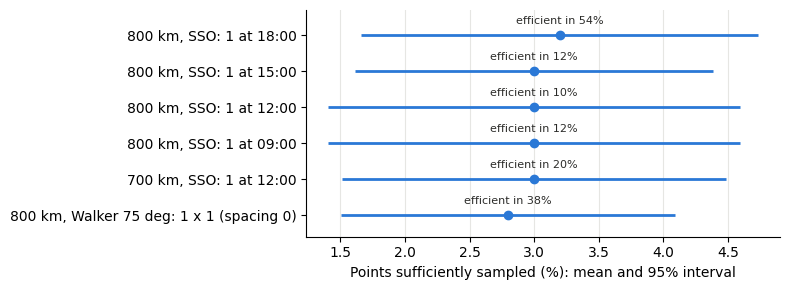

In [3]:
import matplotlib.pyplot as plt

from tatc.tradespace import style_axes
from tatc.tradespace.plotting import COLORS, GRAY, INK

single = candidates[candidates.satellites == 1].sort_values("sufficient")
fig, ax = plt.subplots(figsize=(8, 3))
rows = range(len(single))
ax.errorbar(single.sufficient, rows, xerr=2 * single["sufficient se"], fmt="o", color=COLORS[0], ms=6, lw=2, capsize=0)
for k, row in enumerate(single.itertuples()):
    ax.annotate(
        f"efficient in {row.pareto_probability:.0%}",
        (row.sufficient, k),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color=INK,
    )
ax.set_yticks(rows, single.description.str.replace(", 60 deg FOR", ""))
ax.set(xlabel="Points sufficiently sampled (%): mean and 95% interval", ylim=(-0.6, len(single) - 0.3))
style_axes(ax, grid="x")
fig.tight_layout()
plt.show()

Four of the seven efficient designs are efficient in every resample, and two more nearly so: two satellites in one plane (98%) and four in two planes (92%). The single satellite is not settled. One crossing the equator at 18:00 is efficient in 54% of the resamples, one in a Walker orbit inclined 75 degrees in 38%, and others in 10 to 20%. Likewise, three satellites in three planes (29% and 32%) sample about as many points as three in one plane, and six satellites in two planes with another phasing (32%) as many as the efficient design. Given five replicates, these designs are equally good candidates.

## Refine Uncertain Designs

More replicates of every design would settle the front, at the cost of evaluating every design again for each. `refine` adds replicates only to the designs whose efficiency is uncertain (efficient in more than 5% and fewer than 95% of the resamples), five at a time, until none is uncertain or a design has 40 replicates.

Some differences are too small to matter, and too small to settle: a tenth of a percentage point between designs that sample nearly every point. A **tolerance** treats the designs within it of the front as efficient. Here, differences of less than 1 percentage point do not matter. The tolerance is part of the `Criteria` by which designs are judged. `refine` also stops refining a design once its share is known to within half the tolerance (a standard error of 0.5 points): the design is then **indifferent**.

In [4]:
from tatc.tradespace import Criteria, refine

CRITERIA = Criteria(OBJECTIVES, tolerance={"sufficient": 1.0})  # percentage points that do not matter
refinement = refine(study, CRITERIA, results, step=5, max_replicates=40, n_resamples=1000)
added = len(refinement.results) - len(results)
print(f"{added} evaluations added, {added / (len(designs) * 35):.1%} of those of 40 replicates of every design")
refinement.history

215 evaluations added, 0.6% of those of 40 replicates of every design


,round,uncertain,indifferent,refined,evaluations
0,0,31,2,29,145
1,1,16,11,5,25
2,2,14,11,3,15
3,3,14,12,2,10
4,4,14,13,1,5
5,5,14,13,1,5
6,6,14,12,2,10
7,7,13,12,0,0


In [5]:
refined = refinement.summary
refined["description"] = refined.apply(describe, axis=1)
print(f"{refined.pareto.sum()} designs are efficient within the tolerance; the designs refined:")
refined[refined.replicates > 5].sort_values(["satellites", "planes", "sufficient"])[
    ["description", "satellites", "planes", "sufficient", "replicates", "pareto", "pareto_probability", "indifferent"]
].round(2)

39 designs are efficient within the tolerance; the designs refined:


,description,satellites,planes,sufficient,replicates,pareto,pareto_probability,indifferent
224,"500 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,1.40,10,False,0.01,False
226,"500 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,1.40,10,False,0.01,False
228,"500 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,1.60,10,False,0.02,False
743,"700 km, 60 deg FOR, Walker 75 deg: 1 x 1 (spac...",1.0,1.0,1.60,10,False,0.04,False
232,"500 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,1.70,10,False,0.03,False
500,"600 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,1.80,10,False,0.12,True
230,"500 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,1.90,10,False,0.14,True
498,"600 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,1.90,10,False,0.19,True
504,"600 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,2.10,10,False,0.18,True
502,"600 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,2.20,10,True,0.40,True


Refinement adds 215 evaluations, 0.6% of those that 40 replicates of every design would take, to 31 designs. One round of five replicates settles most of them, as efficient or not, and a few take more. With the tolerance, 39 designs are efficient candidates, among them every design of six to nine satellites that samples about 98% of the points: they differ by less than matters.

The single satellites that refinement leaves indifferent sample 1.8 to 2.5% of the points, about one tolerance below the best (3.2%). More replicates would settle only whether they fall within the tolerance, which does not change the trade, so refinement stops once their shares are known to within half the tolerance. Three satellites in three planes vary more between replicates: one design is indifferent after 25 replicates, and another remains uncertain at 40.

## Confirm the Front

The efficient designs were chosen for their means, and so in part for luck: among a thousand designs, those that look best are likely to have drawn favorable samples of points. `confirm` evaluates the chosen designs (by default, the front of the results it is given) with new replicates, which played no part in choosing them. The difference between the means of the replicates that chose a design and those of the new ones is the **optimism** of the choice.

In [6]:
from tatc.tradespace import confirm

confirmation = confirm(study, CRITERIA, refinement.results, replicates=20)  # 20 new replicates of the front
confirmed = confirmation.summary
confirmed["description"] = confirmed.apply(describe, axis=1)
confirmed["optimism"] = confirmed["sufficient selected"] - confirmed["sufficient"]
print(f"{len(confirmed)} designs confirmed, of which {confirmed.pareto.sum()} are efficient by the new replicates")
print(f"mean optimism: {confirmation.optimism()['sufficient']:.2f} percentage points")
print("mean optimism by number of satellites:", confirmed.groupby("satellites").optimism.mean().round(2).to_dict())
# the middle of the front: two to four satellites
confirmed[confirmed.satellites.between(2, 4)].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient selected", "sufficient", "optimism", "pareto"]
].round(2)

39 designs confirmed, of which 35 are efficient by the new replicates
mean optimism: -0.02 percentage points
mean optimism by number of satellites: {1.0: -0.39, 2.0: 0.85, 3.0: 2.09, 4.0: 2.45, 6.0: -0.18, 8.0: -0.34, 9.0: -0.34}


,description,satellites,planes,sufficient selected,sufficient,optimism,pareto
17,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,16.60,16.15,0.45,True
20,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.20,28.95,1.25,True
18,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,38.00,36.70,1.30,True
22,"800 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...",3.0,3.0,38.48,35.60,2.88,False
19,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,68.20,66.50,1.70,True
21,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,69.60,66.40,3.20,True


The optimism of every confirmed design, by its number of satellites (designs that are no longer efficient by the new replicates are hollow):

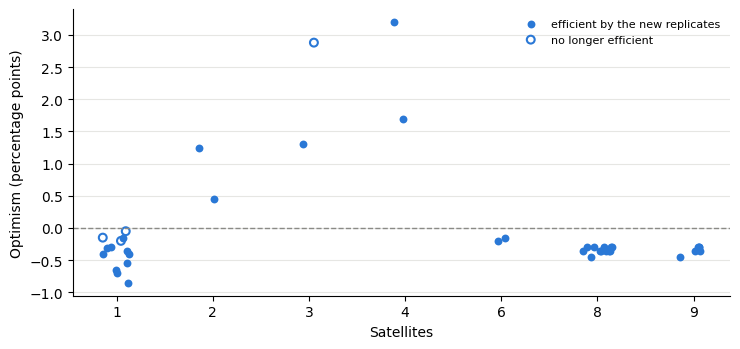

In [7]:
import numpy as np

positions = {n: k for k, n in enumerate(sorted(confirmed.satellites.unique()))}
x = confirmed.satellites.map(positions).to_numpy() + np.random.default_rng(0).uniform(-0.15, 0.15, len(confirmed))
still = confirmed.pareto.to_numpy(dtype=bool)
optimism = confirmed.optimism.to_numpy()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.axhline(0, color=GRAY, lw=1, ls="--")
ax.scatter(x[still], optimism[still], s=32, color=COLORS[0], lw=0, label="efficient by the new replicates")
ax.scatter(
    x[~still], optimism[~still], s=32, facecolor="none", edgecolor=COLORS[0], lw=1.5, label="no longer efficient"
)
ax.set_xticks(list(positions.values()), [f"{n:.0f}" for n in positions])
ax.set(xlabel="Satellites", ylabel="Optimism (percentage points)")
ax.legend(loc="upper right", fontsize=8, frameon=False)
style_axes(ax)
fig.tight_layout()
plt.show()

The designs of two to four satellites sample up to 3.2 points fewer with the new replicates (2.5 points on average for four satellites): four satellites in two planes sample 66.4% rather than 69.6%. The three satellites in three planes, which refinement left as good as three in one plane, sample 35.6% and are no longer efficient.

The single satellites and the designs of six to nine satellites sample slightly more with the new replicates instead (by 0.2 to 0.4 points on average): the new samples of points happen to be easier to sample. The designs share their samples, so this difference applies to every design alike, and is not optimism. The mean optimism over all the designs (-0.02 points) mixes the two, so compare designs one by one. 35 of the 39 designs remain efficient: the shape of the front holds, but its middle is up to 3 points less good than it looked.

## Require Reliable Sampling

A mean does not say how reliably a design performs, as its share differs between samples of points. Other statistics over the replicates judge designs by their reliability:

* `Quantile("sufficient", 0.2)`: the share that a design exceeds in 80% of the samples;
* `Probability("sufficient", ">=", 50)`: the share of the samples in which a design samples at least half of the points sufficiently.

A `Requirement` on a statistic rules out the designs that do not meet it. Here, the objective is the 0.2 quantile, and a design must sample half of the points sufficiently in at least 80% of the samples. The `Criteria` hold the objectives, the statistics that they name, and the requirements.

In [8]:
from tatc.tradespace import Probability, Quantile, Requirement

RELIABLE = Criteria(
    {"satellites": "min", "planes": "min", "sufficient p20": "max"},
    statistics={
        "sufficient p20": Quantile("sufficient", 0.2),
        "reliability": Probability("sufficient", ">=", 50),
    },
    requirements=[Requirement("reliability", ">=", 0.8)],
)
reliable = pareto_probability(refinement.results, RELIABLE, n_resamples=1000)
reliable["description"] = reliable.apply(describe, axis=1)
print(f"{reliable.meets_requirements.sum()} of {len(reliable)} designs meet the requirement")
reliable[reliable.pareto_probability >= 0.1].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient p20", "reliability", "replicates", "pareto_probability"]
].round(2)

209 of 1096 designs meet the requirement


,description,satellites,planes,sufficient p20,reliability,replicates,pareto_probability
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,65.0,1.0,5,1.00
965,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,68.0,1.0,5,0.94
1025,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.8,1.0,5,1.00
1026,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.0,1.0,5,0.50


The replicates of these designs, and of the most reliable design of three satellites, against the threshold of half of the points (dashed): a design meets the requirement if at least 80% of its replicates lie right of the threshold, and its objective is the share that 80% of them exceed (its 0.2 quantile, the tick).

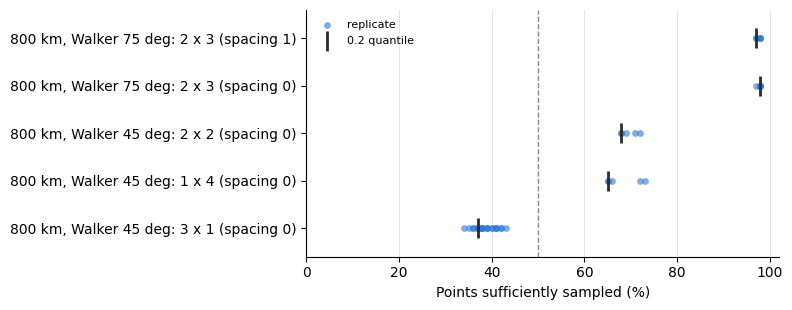

In [9]:
import pandas as pd

three = reliable[reliable.satellites == 3].nlargest(1, "sufficient p20")
shown = pd.concat([three, reliable[reliable.pareto_probability >= 0.1]]).sort_values(["satellites", "planes"])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.axvline(50, color=GRAY, lw=1, ls="--")
for k, (_, row) in enumerate(shown.iterrows()):
    shares = refinement.results.loc[refinement.results.design == row.design, "sufficient"].to_numpy()
    ax.scatter(
        shares, np.full(len(shares), k), s=24, color=COLORS[0], alpha=0.6, lw=0, label="replicate" if k == 0 else None
    )
    ax.scatter(row["sufficient p20"], k, marker="|", s=200, color=INK, lw=2, label="0.2 quantile" if k == 0 else None)
ax.set_yticks(range(len(shown)), shown.description.str.replace(", 60 deg FOR", ""))
ax.set(xlabel="Points sufficiently sampled (%)", xlim=(0, 102), ylim=(-0.6, len(shown) - 0.4))
ax.legend(loc="upper left", fontsize=8, frameon=False)
style_axes(ax, grid="x")
fig.tight_layout()
plt.show()

209 of the 1,096 designs meet the requirement, none of them with fewer than four satellites. Among them, four satellites in one plane and six in two planes are efficient for sure, sampling at least 65% and 98% of the points in 80% of the samples. Four satellites in two planes sample more than four in one (at least 68%), and are efficient in 94% of the resamples: these are the alternatives to weigh against the cost of a second plane.

## Summary

* The front of the means of the replicates is uncertain: `pareto_probability` finds the designs whose efficiency the replicates settle, and those that are equally good candidates.
* `refine` adds replicates only to the designs whose efficiency is uncertain, ignoring differences within a tolerance (part of the `Criteria`).
* `confirm` evaluates the chosen designs with new replicates, which measures the optimism of choosing the best of many nearly equal designs.
* Statistics other than means (such as a `Quantile`, or the `Probability` of meeting a threshold) judge how reliably a design performs, and `Requirement`s on them rule out designs.
* Each of these steps takes the study, the criteria, and the results of the step before (or of a search, see `SearchTradeSpace`), and gives its own results and a summary of its designs.

The next notebook, `CompareScenarios`, compares designs under conditions that are not known in advance.

## Notes

* A `budget` of `refine` limits its evaluations, refining the least settled designs first.
* An absolute tolerance suits a share near 100% better than a share near 0%; a tolerance proportional to the objective would treat both alike.